<a href="https://colab.research.google.com/github/TatekBelay/GEARS/blob/master/GOSIF_v3_download_clip_Final_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Download GOSIF v3 (8-day SIF) and clip to your study area

This notebook downloads 8-day GOSIF solar-induced chlorophyll fluorescence (SIF) files from the
Global Ecology Group Data Repository (University of New Hampshire) for 1 Jan 2000 – 31 Dec 2025,
clips each one to your shapefile, and produces:
- one clipped GeoTIFF per 8-day date (`GOSIF_YYYYDDD_clip.tif`);
- one multi-band GeoTIFF time series, one band per date in date order
  (`GOSIF_v3_8day_SIF_timeseries_2000_2025.tif`), with a CSV of each band's start and end dates;
- a completeness report, including the 2000 dates for which no GOSIF data exist
  (the record starts on 26 Feb 2000).

**Source:** https://data.globalecology.unh.edu/data/GOSIF_v3/8day/

**How to use it**
1. Choose **Runtime → Run all**.
2. Allow access to Google Drive when asked.
3. The first time, sign in to Google Earth Engine when asked. The study area is read from your
   asset `projects/ee-tatekbelay/assets/Taiwan_New`, saved in Drive and reused afterwards.
   (To upload a shapefile instead, set `AOI_SOURCE = "upload"` in Section 2.)
4. Let it run. The first file is checked automatically before the full download starts.
5. If Colab disconnects, choose **Runtime → Run all** again. Finished files are skipped.
   Repeat until Section 7 prints "Complete".

**Good to know**
- Each global 8-day file must be downloaded whole (about 9–10 MB compressed) before it can be
  clipped, so 2000–2025 means roughly 1,190 files and about 11 GB of downloads, which can take one to
  several hours. Clipped outputs are tiny. Keep the Colab tab open.
- All outputs are saved in Google Drive → My Drive → `GOSIF_v3_8day_clipped`.
- Data facts (from the GOSIF v3 readme): 0.05° resolution, geographic coordinates, scale factor
  0.0001, units W m⁻² µm⁻¹ sr⁻¹, fill values 32767 (water) and 32766 (permanent snow/ice).

**Citation and fair use:** cite Li & Xiao (2019), *Remote Sensing*, 11, 517,
https://doi.org/10.3390/rs11050517, and read the repository's fair-use policy:
https://data.globalecology.unh.edu/data/GOSIF_v3/Fair_Data_Use_Policy_and_Readme_GOSIF_v3.pdf

## 1. Install and import packages
**Always run this cell first**, including after any runtime restart or disconnect
(a restart clears all imports and settings). The easiest way: Runtime → Run all.

In [1]:
!pip install -q rasterio geopandas

import os, re, io, gzip, glob, time, shutil, zipfile, threading
from datetime import date, datetime, timedelta
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd
import requests
import geopandas as gpd
import rasterio
from rasterio.io import MemoryFile
from rasterio.features import geometry_mask
from rasterio.transform import from_origin
from rasterio.windows import Window, transform as window_transform
from affine import Affine
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

print("rasterio", rasterio.__version__, "| geopandas", gpd.__version__)

rasterio 1.5.2 | geopandas 1.2.0


## 2. Settings
Edit these values, then run the cell.

In [2]:
BASE_URL = "https://data.globalecology.unh.edu/data/GOSIF_v3/8day/"

# Study area source:
#   "gee"    = read your Google Earth Engine asset directly (no shapefile upload needed)
#   "upload" = upload a shapefile / .zip / .gpkg / .geojson from your computer
AOI_SOURCE  = "gee"
GEE_ASSET   = "projects/ee-tatekbelay/assets/Taiwan_New"
GEE_PROJECT = "ee-tatekbelay"   # the Cloud project that owns the asset

# Period to download (inclusive). Files are matched by the start date of each 8-day composite.
# Note: GOSIF begins on 26 Feb 2000 (GOSIF_2000057). Earlier 2000 dates do not exist on the server;
# Section 4 lists them so the gap is documented, not silent.
START_DATE = "2000-01-01"
END_DATE   = "2025-12-31"

# Where to save results. With USE_DRIVE = True, outputs survive a Colab disconnect.
USE_DRIVE  = True
OUTPUT_DIR = "/content/drive/MyDrive/GOSIF_v3_8day_clipped"   # used when USE_DRIVE = True
LOCAL_DIR  = "/content/GOSIF_v3_8day_clipped"                 # used when USE_DRIVE = False

# "scaled": float32 SIF in W m-2 um-1 sr-1, scale factor applied, fill values set to NaN (recommended).
# "raw":    original integer values, unscaled; 32767 is written as nodata, 32766 (snow/ice) is kept.
OUTPUT_MODE = "scaled"

# True keeps every 0.05° pixel the boundary touches. Recommended for small or coastal study areas,
# where pixels are large compared with the area (one pixel is about 5.5 km).
ALL_TOUCHED = True

# Optional buffer around the study area, in degrees (0 = none; 0.05 = about one pixel).
BUFFER_DEG = 0.0

# Parallel downloads. Keep this small (2–4) to be polite to the server.
MAX_WORKERS = 4

# False = full 2000-2025 run (default). True = process only 3 files for a quick look.
TEST_RUN = False

# Automatic georeferencing check on the first file before the full download (recommended).
# It stops the run if less than this share of the pixels inside your study area hold valid
# (land) SIF values, which would mean the data are misplaced (e.g. falling on the sea).
CHECK_GEOREF = True
MIN_VALID_SHARE = 0.5

# Downloads to your computer at the end (Section 10). Everything is also kept in Google Drive.
DOWNLOAD_TIMESERIES = True   # the time-series GeoTIFF + its band-date CSV + mean-SIF CSV
MAKE_ZIP = True              # one zip of ALL outputs (every per-date GeoTIFF, CSVs, study area)

# How many times to retry files that fail (network errors etc.) before giving up.
MAX_PASSES = 5

# Name of the multi-band GeoTIFF time series built in Section 8 (one band per 8-day date).
STACK_NAME = "GOSIF_v3_8day_SIF_timeseries_2000_2025.tif"

# --- GOSIF product constants (from the v3 readme) ---
SCALE_FACTOR = 0.0001
FILL_VALUES  = (32767, 32766)   # 32767 = water bodies, 32766 = land under snow/ice all year

In [3]:
if "rasterio" not in globals():
    raise RuntimeError("Packages are not loaded in this session. Run the Section 1 cell first "
                       "(or use Runtime → Run all), then run this cell again.")

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = OUTPUT_DIR
else:
    OUT = LOCAL_DIR
os.makedirs(OUT, exist_ok=True)
print("Clipped files will be saved in:", OUT)

Mounted at /content/drive
Clipped files will be saved in: /content/drive/MyDrive/GOSIF_v3_8day_clipped


## 3. Your study area
With `AOI_SOURCE = "gee"` (default), the study area is read directly from your Earth Engine asset
`projects/ee-tatekbelay/assets/Taiwan_New`. The first time, you are asked to sign in to Earth Engine
(choose the Google account that owns the asset and allow access).

With `AOI_SOURCE = "upload"`, you upload a shapefile instead: select **all** parts at once
(`.shp`, `.shx`, `.dbf`, `.prj`), or one `.zip`. A `.gpkg` or `.geojson` also works.

The study area is then saved in your output folder (`study_area` subfolder) and reused
automatically after a disconnect. To change the study area, delete that `study_area` folder first.

In [4]:
from google.colab import files

SHP_DIR = os.path.join(OUT, "study_area")
os.makedirs(SHP_DIR, exist_ok=True)

def find_vector(folder):
    return (sorted(glob.glob(os.path.join(folder, "**", "*.shp"), recursive=True))
            + sorted(glob.glob(os.path.join(folder, "**", "*.gpkg"), recursive=True))
            + sorted(glob.glob(os.path.join(folder, "**", "*.geojson"), recursive=True)))

candidates = find_vector(SHP_DIR)
if candidates:
    print("Reusing the saved study area:", candidates[0])
elif AOI_SOURCE == "gee":
    import json, ee
    print("Sign in to Google Earth Engine when asked...")
    ee.Authenticate()
    ee.Initialize(project=GEE_PROJECT)
    fc = ee.FeatureCollection(GEE_ASSET)
    # Light simplification (100 m) keeps the download small; GOSIF pixels are ~5.5 km, so it has no effect on clipping.
    geojson = fc.map(lambda f: f.simplify(100)).getInfo()
    gee_path = os.path.join(SHP_DIR, GEE_ASSET.split("/")[-1] + ".geojson")
    with open(gee_path, "w") as f:
        json.dump(geojson, f)
    print(f"Saved {len(geojson['features'])} feature(s) from {GEE_ASSET} to {gee_path}")
    candidates = [gee_path]
else:
    uploaded = files.upload()
    for name, content in uploaded.items():
        path = os.path.join(SHP_DIR, name)
        with open(path, "wb") as f:
            f.write(content)
        if name.lower().endswith(".zip"):
            with zipfile.ZipFile(path) as z:
                z.extractall(SHP_DIR)
    candidates = find_vector(SHP_DIR)
    if not candidates:
        raise FileNotFoundError("No .shp, .gpkg or .geojson file found. Upload all shapefile parts or a .zip.")
VECTOR_PATH = candidates[0]
print("Using:", VECTOR_PATH)

Sign in to Google Earth Engine when asked...


/usr/local/lib/python3.13/dist-packages/ee/data.py:335: UserWarning: Your project has exceeded the compute quota of its noncommercial tier and is currently in restricted mode.
  warnings.warn(


Saved 19 feature(s) from projects/ee-tatekbelay/assets/Taiwan_New to /content/drive/MyDrive/GOSIF_v3_8day_clipped/study_area/Taiwan_New.geojson
Using: /content/drive/MyDrive/GOSIF_v3_8day_clipped/study_area/Taiwan_New.geojson


/usr/local/lib/python3.13/dist-packages/ee/data.py:335: UserWarning: Your project has exceeded the compute quota of its noncommercial tier and is currently in restricted mode.
  warnings.warn(


Original CRS: EPSG:4326
Features: 19 | Bounds (lon/lat): 120.027, 21.897, 124.561, 25.924


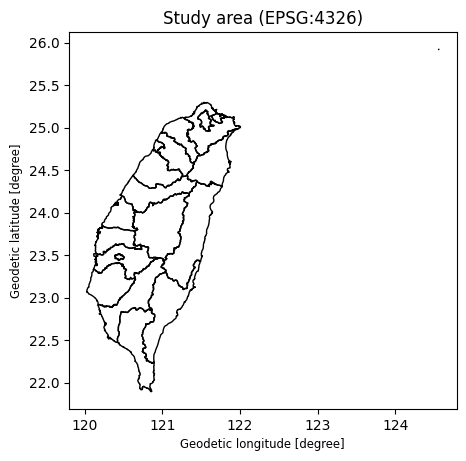

In [5]:
aoi = gpd.read_file(VECTOR_PATH)
if aoi.crs is None:
    raise ValueError(
        "The shapefile has no coordinate system (the .prj file is missing). Upload the .prj file, "
        "or set it here, e.g. aoi = aoi.set_crs('EPSG:3826') for TWD97 / TM2 Taiwan."
    )
print("Original CRS:", aoi.crs)

# GOSIF is in geographic coordinates (WGS 84), so the study area is reprojected to EPSG:4326.
aoi = aoi.to_crs("EPSG:4326")
aoi = aoi[~aoi.geometry.is_empty & aoi.geometry.notna()].copy()
aoi["geometry"] = aoi.geometry.buffer(0)          # repair minor geometry errors
if BUFFER_DEG > 0:
    aoi["geometry"] = aoi.geometry.buffer(BUFFER_DEG)

AOI_SHAPES = [geom.__geo_interface__ for geom in aoi.geometry]
minx, miny, maxx, maxy = aoi.total_bounds
print(f"Features: {len(aoi)} | Bounds (lon/lat): {minx:.3f}, {miny:.3f}, {maxx:.3f}, {maxy:.3f}")

ax = aoi.plot(figsize=(5, 6), edgecolor="black", facecolor="none")
ax.set_title("Study area (EPSG:4326)")
plt.show()

## 4. List the GOSIF files on the server and select your period

In [6]:
def yyyyddd_to_date(year, doy):
    """Convert year + day of year (as in GOSIF_YYYYDDD) to a calendar date."""
    return date(int(year), 1, 1) + timedelta(days=int(doy) - 1)

def list_server_files(base_url):
    """Read the repository's directory listing and return all GOSIF 8-day file names."""
    r = requests.get(base_url, timeout=120)
    r.raise_for_status()
    names = sorted(set(re.findall(r"GOSIF_\d{7}\.tif\.gz", r.text)))
    if not names:
        raise RuntimeError("No GOSIF files found in the directory listing. Open the URL in a browser to check it.")
    return names

def select_files(names, start, end):
    start = datetime.strptime(start, "%Y-%m-%d").date()
    end = datetime.strptime(end, "%Y-%m-%d").date()
    rows = []
    for n in names:
        y, d = int(n[6:10]), int(n[10:13])
        dt = yyyyddd_to_date(y, d)
        if start <= dt <= end:
            rows.append({"file": n, "year": y, "doy": d, "date": dt})
    return pd.DataFrame(rows)

def expected_8day_dates(start, end):
    """All 8-day composite start dates (DOY 1, 9, ..., 361 of each year) between start and end."""
    start = datetime.strptime(start, "%Y-%m-%d").date()
    end = datetime.strptime(end, "%Y-%m-%d").date()
    rows = []
    for y in range(start.year, end.year + 1):
        for d in range(1, 366, 8):
            dt = yyyyddd_to_date(y, d)
            if start <= dt <= end:
                rows.append({"file": f"GOSIF_{y}{d:03d}.tif.gz", "year": y, "doy": d, "date": dt})
    return pd.DataFrame(rows)

for _v in ("OUT", "aoi"):
    if _v not in globals():
        raise RuntimeError("Earlier cells have not been run in this session. Use Runtime → Run all.")

all_names = list_server_files(BASE_URL)
print(f"Files on server: {len(all_names)} ({all_names[0]} to {all_names[-1]})")

todo = select_files(all_names, START_DATE, END_DATE)
print(f"Files available in {START_DATE} to {END_DATE}: {len(todo)}")

# Completeness check against the regular 8-day calendar (46 composites per year)
expected = expected_8day_dates(START_DATE, END_DATE)
not_on_server = expected[~expected["file"].isin(all_names)]
per_year = pd.DataFrame({"expected": expected.groupby("year").size(),
                         "available": todo.groupby("year").size()}).fillna(0).astype(int)
print(per_year.to_string())
if len(not_on_server):
    print(f"\n{len(not_on_server)} 8-day dates in your period are NOT on the server (no data exist for them):")
    print(", ".join(f"{r.date} ({r.file[:13]})" for r in not_on_server.itertuples()))
    not_on_server.to_csv(os.path.join(OUT, "dates_not_available_on_server.csv"), index=False)
else:
    print("\nEvery 8-day date in your period is available on the server.")
print(f"\nApproximate download volume: {len(todo) * 9.5 / 1024:.1f} GB (about 9–10 MB per file)")

Files on server: 1189 (GOSIF_2000057.tif.gz to GOSIF_2025361.tif.gz)
Files available in 2000-01-01 to 2025-12-31: 1189
      expected  available
year                     
2000        46         39
2001        46         46
2002        46         46
2003        46         46
2004        46         46
2005        46         46
2006        46         46
2007        46         46
2008        46         46
2009        46         46
2010        46         46
2011        46         46
2012        46         46
2013        46         46
2014        46         46
2015        46         46
2016        46         46
2017        46         46
2018        46         46
2019        46         46
2020        46         46
2021        46         46
2022        46         46
2023        46         46
2024        46         46
2025        46         46

7 8-day dates in your period are NOT on the server (no data exist for them):
2000-01-01 (GOSIF_2000001), 2000-01-09 (GOSIF_2000009), 2000-01-17 (GOSIF_2

## 5. Download-and-clip functions

In [7]:
_thread = threading.local()

def _session():
    if not hasattr(_thread, "s"):
        _thread.s = requests.Session()
    return _thread.s

def out_name(gz_name):
    stem = gz_name.replace(".tif.gz", "")
    return os.path.join(OUT, f"{stem}_clip.tif")

def download_gz(url, retries=4):
    """Download one .tif.gz file into memory and return the decompressed GeoTIFF bytes."""
    for attempt in range(1, retries + 1):
        try:
            r = _session().get(url, timeout=300)
            r.raise_for_status()
            return gzip.decompress(r.content)          # also detects a truncated download
        except Exception as e:
            if attempt == retries:
                raise RuntimeError(f"Download failed after {retries} tries: {e}")
            time.sleep(5 * attempt)

class NoOverlapError(Exception):
    pass

GRID_RES = 0.05   # GOSIF pixel size in degrees

def grid_transform(src):
    """Return the geotransform of a GOSIF file.

    The GOSIF GeoTIFFs carry no geotransform (rasterio warns 'Dataset has no geotransform'),
    so the global 0.05-degree grid is assigned here: 7200 x 3600 pixels, upper-left corner at
    longitude -180, latitude 90. The function stops if a file has a different size."""
    if src.crs is not None and src.transform != Affine.identity():
        if src.crs.to_epsg() != 4326:
            raise RuntimeError(f"Unexpected raster CRS {src.crs}; expected EPSG:4326.")
        return src.transform
    if (src.width, src.height) != (round(360 / GRID_RES), round(180 / GRID_RES)):
        raise RuntimeError(f"Unexpected raster size {src.width} x {src.height}; expected 7200 x 3600 "
                           "for a global 0.05-degree grid. Georeferencing cannot be assigned safely.")
    return from_origin(-180.0, 90.0, GRID_RES, GRID_RES)

def aoi_window(transform, width, height):
    """Pixel window covering the study area's bounding box (whole pixels, clamped to the grid)."""
    x0, y0, res = transform.c, transform.f, transform.a
    col0 = max(0, int(np.floor((minx - x0) / res)))
    col1 = min(width, int(np.ceil((maxx - x0) / res)))
    row0 = max(0, int(np.floor((y0 - maxy) / res)))
    row1 = min(height, int(np.ceil((y0 - miny) / res)))
    if col1 <= col0 or row1 <= row0:
        raise NoOverlapError("The study area does not overlap the GOSIF grid. Check the shapefile CRS.")
    return Window(col0, row0, col1 - col0, row1 - row0)

CLIP_VERSION = "3"   # written into every output; files without it come from an older, faulty version

def is_valid_output(path):
    """True only for an output written by this version: correct tag, EPSG:4326, 0.05-degree pixels,
    and lying within the study area's bounds. Anything else is deleted and redone."""
    try:
        with rasterio.open(path) as ds:
            b = ds.bounds
            return (ds.tags().get("clip_version") == CLIP_VERSION
                    and ds.crs is not None and ds.crs.to_epsg() == 4326
                    and np.allclose(ds.res, (GRID_RES, GRID_RES))
                    and b.left >= minx - GRID_RES and b.right <= maxx + GRID_RES
                    and b.bottom >= miny - GRID_RES and b.top <= maxy + GRID_RES)
    except Exception:
        return False     # unreadable or half-written file

def clip_one(gz_name):
    """Download one GOSIF file, clip it to the study area and save it. Returns a status string."""
    dst = out_name(gz_name)
    if os.path.exists(dst):
        if is_valid_output(dst):
            return "skipped"
        os.remove(dst)            # output from an older, faulty version: redo it
        status_note = "redone"
    else:
        status_note = "done"
    tif_bytes = download_gz(BASE_URL + gz_name)

    with MemoryFile(tif_bytes) as mem, mem.open() as src:
        transform = grid_transform(src)
        win = aoi_window(transform, src.width, src.height)
        band = src.read(1, window=win)
        src_nodata = src.nodata if src.nodata is not None else FILL_VALUES[0]
    win_transform = window_transform(win, transform)

    # True for pixels outside the study-area polygons
    outside = geometry_mask(AOI_SHAPES, out_shape=band.shape, transform=win_transform,
                            all_touched=ALL_TOUCHED)

    if OUTPUT_MODE == "scaled":
        out = band.astype("float32")
        invalid = outside | np.isin(band, FILL_VALUES) | (band == src_nodata)
        out[invalid] = np.nan
        out *= SCALE_FACTOR
        dtype, nodata = "float32", np.nan
    else:
        out = band.copy()
        out[outside] = src_nodata
        dtype, nodata = str(band.dtype), src_nodata

    profile = dict(driver="GTiff", height=out.shape[0], width=out.shape[1], count=1,
                   dtype=dtype, nodata=nodata, crs="EPSG:4326", transform=win_transform,
                   compress="deflate")

    tmp = dst + ".part"                     # write to a temporary name, then rename,
    with rasterio.open(tmp, "w", **profile) as dst_ds:   # so an interrupted run never
        dst_ds.write(out, 1)                              # leaves a half-written file
        dst_ds.update_tags(source=BASE_URL + gz_name, scale_factor_applied=str(OUTPUT_MODE == "scaled"),
                           units="W m-2 um-1 sr-1" if OUTPUT_MODE == "scaled" else "DN (multiply by 0.0001)",
                           clip_version=CLIP_VERSION)
    os.replace(tmp, dst)
    return status_note

def run(names, workers=MAX_WORKERS):
    status = {"done": 0, "redone": 0, "skipped": 0}
    failed = {}
    with ThreadPoolExecutor(max_workers=workers) as ex:
        futures = {ex.submit(clip_one, n): n for n in names}
        for fut in tqdm(as_completed(futures), total=len(futures), desc="GOSIF"):
            n = futures[fut]
            try:
                status[fut.result()] += 1
            except NoOverlapError:
                ex.shutdown(cancel_futures=True)
                raise
            except Exception as e:
                failed[n] = str(e)
    print(f"New: {status['done']} | Replaced old faulty files: {status['redone']} | "
          f"Already correct (skipped): {status['skipped']} | Failed: {len(failed)}")
    return failed

## 6. Run the full download
1. The first file is processed and checked automatically (georeferencing check).
2. All other 2000–2025 files are then downloaded and clipped, 4 at a time.
3. Failed downloads are retried up to `MAX_PASSES` times.

If Colab disconnects, use Runtime → Run all again: finished files are skipped.

In [8]:
if "todo" not in globals() or "clip_one" not in globals():
    raise RuntimeError("Earlier cells have not been run in this session. Use Runtime → Run all.")

# Remove outputs left by older or faulty runs (any date, not only those processed now).
# Deleted dates are recreated correctly when they are processed.
for p in glob.glob(os.path.join(OUT, "GOSIF_*_clip.tif")):
    if not is_valid_output(p):
        os.remove(p)
        print("Removed old/faulty file:", os.path.basename(p))
for p in glob.glob(os.path.join(OUT, "*.part")):
    os.remove(p)                              # half-written files from an interrupted run

def check_georef(path):
    """Share of pixels inside the study area that hold valid (land) SIF values in one clipped file.
    GOSIF sea pixels are fill values, so a study area on land should be mostly valid."""
    with rasterio.open(path) as ds:
        a = ds.read(1)
        tr = ds.transform
    inside = ~geometry_mask(AOI_SHAPES, out_shape=a.shape, transform=tr, all_touched=False)
    if not inside.any():                       # very small study area: use touched pixels
        inside = ~geometry_mask(AOI_SHAPES, out_shape=a.shape, transform=tr, all_touched=True)
    valid = np.isfinite(a) if OUTPUT_MODE == "scaled" else ~np.isin(a, FILL_VALUES)
    return float(valid[inside].mean()), int(inside.sum())

names = todo["file"].tolist()
if TEST_RUN:
    names = names[:3]
    print("TEST RUN: processing", names)

# Step 1: first file + automatic georeferencing check
first_failed = run(names[:1], workers=1)
if first_failed:
    raise RuntimeError(f"The first file could not be processed: {first_failed}. Check the connection and run again.")
if CHECK_GEOREF:
    share, n_in = check_georef(out_name(names[0]))
    print(f"Georeferencing check on {names[0]}: {share:.0%} of {n_in} pixels inside the study area "
          "hold valid land values.")
    if share < MIN_VALID_SHARE:
        raise RuntimeError(
            "Georeferencing check FAILED: most pixels inside your study area are sea/fill values, so the "
            "data may be misplaced. The full download was not started. Look at the map in Section 7 and "
            "report the result. (If your study area is mostly water, set CHECK_GEOREF = False.)")
    print("Check passed. Starting the full download...")

# Step 2: all remaining files
failed = run(names[1:])

# Keep retrying failures, more slowly each pass, so no available date is missed.
for p in range(2, MAX_PASSES + 1):
    if not failed:
        break
    print(f"Pass {p}/{MAX_PASSES}: retrying {len(failed)} file(s) with 1 worker after a pause...")
    time.sleep(30)
    failed = run(list(failed), workers=1)

fail_csv = os.path.join(OUT, "failed_files.csv")
if failed:
    pd.Series(failed).to_csv(fail_csv, header=["error"])
    print("Still failing (saved to failed_files.csv). Run this cell again later; finished files are skipped:")
    for k, v in failed.items():
        print(" ", k, "->", v)
elif os.path.exists(fail_csv):
    os.remove(fail_csv)

GOSIF:   0%|          | 0/1 [00:00<?, ?it/s]

New: 1 | Replaced old faulty files: 0 | Already correct (skipped): 0 | Failed: 0
Georeferencing check on GOSIF_2000057.tif.gz: 98% of 1281 pixels inside the study area hold valid land values.
Check passed. Starting the full download...


GOSIF:   0%|          | 0/1188 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/rasterio/features.py:381: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  _rasterize(


New: 1188 | Replaced old faulty files: 0 | Already correct (skipped): 0 | Failed: 0


## 7. Check the result
Reports whether every available date was processed and maps the first date. GOSIF sets sea pixels
to a fill value, so the coloured pixels should sit on land and line up with your coastline (black line).

Clipped files in output folder: 1189
Complete: all 1189 available 8-day dates in 2000-01-01 to 2025-12-31 are processed.
GOSIF_2000057_clip.tif | size: 92 x 82 | CRS: EPSG:4326 | pixel: (0.05, 0.05)


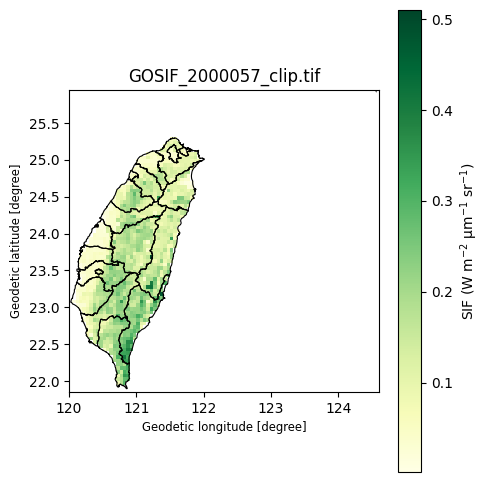

In [9]:
clipped = sorted(glob.glob(os.path.join(OUT, "GOSIF_*_clip.tif")))
print(f"Clipped files in output folder: {len(clipped)}")
bad = [os.path.basename(p) for p in clipped if not is_valid_output(p)]
if bad:
    print(f"WARNING: {len(bad)} file(s) are from an older, faulty version and will be replaced "
          f"when you run Section 6 again: {bad[:5]}")
clipped = [p for p in clipped if os.path.basename(p) not in bad]

expected_out = {out_name(n) for n in todo["file"]}
missing = sorted(expected_out - set(clipped))
if not TEST_RUN:
    if missing:
        print(f"WARNING: {len(missing)} available date(s) are not yet processed. Run Section 6 again:")
        print(", ".join(os.path.basename(m) for m in missing))
    else:
        print(f"Complete: all {len(expected_out)} available 8-day dates in {START_DATE} to {END_DATE} are processed.")

if clipped:
    with rasterio.open(clipped[0]) as ds:
        img = ds.read(1, masked=True)
        ext = [ds.bounds.left, ds.bounds.right, ds.bounds.bottom, ds.bounds.top]
        print(os.path.basename(clipped[0]), "| size:", ds.width, "x", ds.height,
              "| CRS:", ds.crs, "| pixel:", ds.res)
    fig, ax = plt.subplots(figsize=(5, 6))
    im = ax.imshow(img, extent=ext, cmap="YlGn")
    aoi.boundary.plot(ax=ax, color="black", linewidth=0.8)
    plt.colorbar(im, ax=ax, label="SIF (W m$^{-2}$ µm$^{-1}$ sr$^{-1}$)" if OUTPUT_MODE == "scaled" else "DN")
    ax.set_title(os.path.basename(clipped[0]))
    plt.show()

## 8. Build the GeoTIFF time series (one band per 8-day date)
Combines all clipped dates into one multi-band GeoTIFF, in date order. Each band's description is
its start date (e.g. `2000-02-26`). A companion CSV, `..._band_dates.csv`, lists for every band the
composite start and end dates, so SIF can be matched to your daily drought and heatwave records.
Each composite covers 8 days; the last one of each year covers only the days left in that year.

If any available date is still missing, the file is saved with `_INCOMPLETE` in its name.

In [10]:
def composite_end(start_dt):
    """Last day covered by an 8-day composite (the final composite of a year stops at 31 Dec)."""
    return min(start_dt + timedelta(days=7), date(start_dt.year, 12, 31))

clipped = sorted(glob.glob(os.path.join(OUT, "GOSIF_*_clip.tif")))
if not clipped:
    raise RuntimeError("No clipped files found. Run Section 6 first.")
bad = [p for p in clipped if not is_valid_output(p)]
for p in bad:                                  # stale files from older runs: never stack them
    os.remove(p)
    print("Removed old/faulty file (it will be redone by Section 6):", os.path.basename(p))
clipped = [p for p in clipped if p not in bad]
if not clipped:
    raise RuntimeError("No valid clipped files found. Run Section 6 first.")

bands = []
for f in clipped:
    code = re.search(r"GOSIF_(\d{4})(\d{3})_clip", os.path.basename(f))
    y, d = int(code.group(1)), int(code.group(2))
    s = yyyyddd_to_date(y, d)
    sd, ed = datetime.strptime(START_DATE, "%Y-%m-%d").date(), datetime.strptime(END_DATE, "%Y-%m-%d").date()
    if sd <= s <= ed:
        bands.append({"path": f, "file": os.path.basename(f), "year": y, "doy": d,
                      "start_date": s, "end_date": composite_end(s)})
if not bands:
    raise RuntimeError(f"No clipped files fall between {START_DATE} and {END_DATE}.")
bands = pd.DataFrame(bands).sort_values("start_date").reset_index(drop=True)
bands.insert(0, "band", np.arange(1, len(bands) + 1))

# All dates must share the same grid before stacking
with rasterio.open(bands.path[0]) as ref:
    ref_profile = ref.profile.copy()
    ref_key = (ref.width, ref.height, tuple(ref.transform), str(ref.crs), ref.dtypes[0])
for p in bands.path:
    with rasterio.open(p) as ds:
        if (ds.width, ds.height, tuple(ds.transform), str(ds.crs), ds.dtypes[0]) != ref_key:
            raise RuntimeError(f"{os.path.basename(p)} has a different grid from {bands.file[0]}. "
                               "Delete it and run Section 6 again.")

n_missing = len({out_name(n) for n in todo["file"]} - set(bands.path))
stack_name = STACK_NAME if n_missing == 0 else STACK_NAME.replace(".tif", "_INCOMPLETE.tif")
stack_path = os.path.join(OUT, stack_name)

profile = ref_profile
profile.update(count=len(bands), compress="deflate", BIGTIFF="IF_SAFER")
tmp = stack_path + ".part"
with rasterio.open(tmp, "w", **profile) as dst_ds:
    for r in tqdm(bands.itertuples(), total=len(bands), desc="Stacking"):
        with rasterio.open(r.path) as ds:
            dst_ds.write(ds.read(1), r.band)
        dst_ds.set_band_description(r.band, str(r.start_date))
        dst_ds.update_tags(r.band, start_date=str(r.start_date), end_date=str(r.end_date),
                           source_file=r.file.replace("_clip.tif", ".tif.gz"))
    dst_ds.update_tags(product="GOSIF v3, 8-day, 0.05 degree (Li & Xiao, 2019)",
                       units="W m-2 um-1 sr-1" if OUTPUT_MODE == "scaled" else "DN (multiply by 0.0001)",
                       first_date=str(bands.start_date.iloc[0]), last_date=str(bands.start_date.iloc[-1]),
                       n_bands=str(len(bands)))
os.replace(tmp, stack_path)

dates_csv = stack_path.replace(".tif", "_band_dates.csv")
bands.drop(columns="path").to_csv(dates_csv, index=False)

# Once the complete time series exists, remove any older _INCOMPLETE version and its date table
if n_missing == 0:
    old = os.path.join(OUT, STACK_NAME.replace(".tif", "_INCOMPLETE.tif"))
    for p in (old, old.replace(".tif", "_band_dates.csv")):
        if os.path.exists(p):
            os.remove(p)
            print("Removed older incomplete file:", os.path.basename(p))

print(f"Saved: {stack_path}")
print(f"Bands: {len(bands)} | {bands.start_date.iloc[0]} to {bands.end_date.iloc[-1]}")
print(f"Band date table: {dates_csv}")
if n_missing:
    print(f"WARNING: {n_missing} available date(s) are missing. Run Section 6 again, then this cell.")

Stacking:   0%|          | 0/1189 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/GOSIF_v3_8day_clipped/GOSIF_v3_8day_SIF_timeseries_2000_2025.tif
Bands: 1189 | 2000-02-26 to 2025-12-31
Band date table: /content/drive/MyDrive/GOSIF_v3_8day_clipped/GOSIF_v3_8day_SIF_timeseries_2000_2025_band_dates.csv


## 9. Optional: study-area mean time series (CSV)
Saves `GOSIF_index_timeseries.csv` with the date, mean SIF and number of valid pixels for each file.
The mean is unweighted by pixel area, which is a reasonable approximation for a small study area.

Summarising:   0%|          | 0/1189 [00:00<?, ?it/s]

                     file  year  doy        date  mean_sif  valid_pixels
0  GOSIF_2000057_clip.tif  2000   57  2000-02-26  0.141757          1254
1  GOSIF_2000065_clip.tif  2000   65  2000-03-05  0.161048          1254
2  GOSIF_2000073_clip.tif  2000   73  2000-03-13  0.169646          1254
3  GOSIF_2000081_clip.tif  2000   81  2000-03-21  0.179842          1254
4  GOSIF_2000089_clip.tif  2000   89  2000-03-29  0.190486          1254


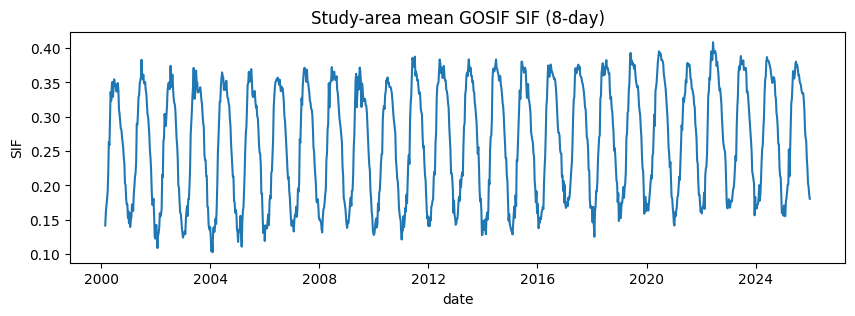

In [11]:
rows = []
for f in tqdm(clipped, desc="Summarising"):
    code = re.search(r"GOSIF_(\d{4})(\d{3})_clip", os.path.basename(f))
    y, d = int(code.group(1)), int(code.group(2))
    with rasterio.open(f) as ds:
        a = ds.read(1).astype("float64")
        if OUTPUT_MODE == "raw":
            a[np.isin(a, FILL_VALUES)] = np.nan
            a *= SCALE_FACTOR
    rows.append({"file": os.path.basename(f), "year": y, "doy": d,
                 "date": yyyyddd_to_date(y, d),
                 "mean_sif": float(np.nanmean(a)) if np.isfinite(a).any() else np.nan,
                 "valid_pixels": int(np.isfinite(a).sum())})

ts = pd.DataFrame(rows, columns=["file", "year", "doy", "date", "mean_sif", "valid_pixels"]).sort_values("date")
ts.to_csv(os.path.join(OUT, "GOSIF_index_timeseries.csv"), index=False)
print(ts.head() if len(ts) else "No clipped files yet.")
if len(ts) > 1:
    ts.plot(x="date", y="mean_sif", figsize=(10, 3), legend=False,
            title="Study-area mean GOSIF SIF (8-day)").set_ylabel("SIF")
    plt.show()

## 10. Download the results to your computer
Downloads, one after another:
1. the time-series GeoTIFF (`GOSIF_v3_8day_SIF_timeseries_2000_2025.tif`),
2. its band-date table (`..._band_dates.csv`) and the mean-SIF table (`GOSIF_index_timeseries.csv`),
3. a zip of all outputs (`GOSIF_v3_8day_clipped.zip`), if `MAKE_ZIP = True`.

Your browser may ask whether to **allow multiple downloads** from Colab: choose Allow.
If a download does not start, the same files are in Google Drive → My Drive → `GOSIF_v3_8day_clipped`.

In [12]:
from google.colab import files

to_download = []

if DOWNLOAD_TIMESERIES:
    stack_tif = os.path.join(OUT, STACK_NAME)
    stack_incomplete = os.path.join(OUT, STACK_NAME.replace(".tif", "_INCOMPLETE.tif"))
    if os.path.exists(stack_tif):
        chosen = stack_tif
    elif os.path.exists(stack_incomplete):
        chosen = stack_incomplete
        print("WARNING: only the INCOMPLETE time series exists. Run Sections 6 and 8 again to complete it.")
    else:
        chosen = None
        print("No time-series GeoTIFF found. Run Section 8 first.")
    if chosen:
        to_download.append(chosen)
        for extra in (chosen.replace(".tif", "_band_dates.csv"),
                      os.path.join(OUT, "GOSIF_index_timeseries.csv")):
            if os.path.exists(extra):
                to_download.append(extra)

if MAKE_ZIP:
    zip_path = shutil.make_archive("/content/GOSIF_v3_8day_clipped", "zip", OUT)
    print(f"Created {zip_path} ({os.path.getsize(zip_path) / 1e6:.1f} MB)")
    to_download.append(zip_path)

for p in to_download:
    print("Downloading:", os.path.basename(p))
    files.download(p)
    time.sleep(3)          # short pause so the browser handles each download

print(f"All outputs are also in Google Drive: {OUT}")

Created /content/GOSIF_v3_8day_clipped.zip (12.6 MB)
Downloading: GOSIF_v3_8day_SIF_timeseries_2000_2025.tif


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: GOSIF_v3_8day_SIF_timeseries_2000_2025_band_dates.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (3 outputs left out)

Downloading: GOSIF_v3_8day_clipped.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

All outputs are also in Google Drive: /content/drive/MyDrive/GOSIF_v3_8day_clipped
